In [36]:
import numpy as np
import pandas as pd
from sklearn.preprocessing  import StandardScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split

In [37]:
df = pd.read_csv('../notebooks/EDA_Completed.csv')

In [38]:
df

,Unnamed: 0,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,Target
0,0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,0
1,1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,0
2,2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,0
3,3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,0
4,4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45206,45206,51,technician,married,tertiary,no,825,no,no,cellular,17,nov,977,3,-1,0,unknown,1
45207,45207,71,retired,divorced,primary,no,1729,no,no,cellular,17,nov,456,2,-1,0,unknown,1
45208,45208,72,retired,married,secondary,no,5715,no,no,cellular,17,nov,1127,5,184,3,success,1
45209,45209,57,blue-collar,married,secondary,no,668,no,no,telephone,17,nov,508,4,-1,0,unknown,0


In [39]:
df = df.drop(columns=['Unnamed: 0'])

In [40]:
df.reset_index()

,index,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,Target
0,0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,0
1,1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,0
2,2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,0
3,3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,0
4,4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45206,45206,51,technician,married,tertiary,no,825,no,no,cellular,17,nov,977,3,-1,0,unknown,1
45207,45207,71,retired,divorced,primary,no,1729,no,no,cellular,17,nov,456,2,-1,0,unknown,1
45208,45208,72,retired,married,secondary,no,5715,no,no,cellular,17,nov,1127,5,184,3,success,1
45209,45209,57,blue-collar,married,secondary,no,668,no,no,telephone,17,nov,508,4,-1,0,unknown,0


In [41]:
df = df.drop(columns=["index"], errors="ignore")

In [42]:
df.head(3)

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,Target
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,0
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,0
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,0


In [43]:
df.isnull().sum()

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
Target       0
dtype: int64

In [44]:
print(df.duplicated().sum())

0


In [45]:
df = df.drop_duplicates()

### Outlier Detection

In [46]:
Q1 = df["balance"].quantile(0.25)
Q3 = df["balance"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR


outliers = df[
    (df['balance'] < lower_limit) |
    (df['balance'] > upper_limit)
]

print("Outliers", len(outliers))

Outliers 4729


In [47]:

Q1 = df["balance"].quantile(0.25)
Q3 = df["balance"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[
    (df["balance"] < lower_limit) |
    (df["balance"] > upper_limit)
]

print("Outliers:", len(outliers))


Outliers: 4729


<Axes: xlabel='balance'>

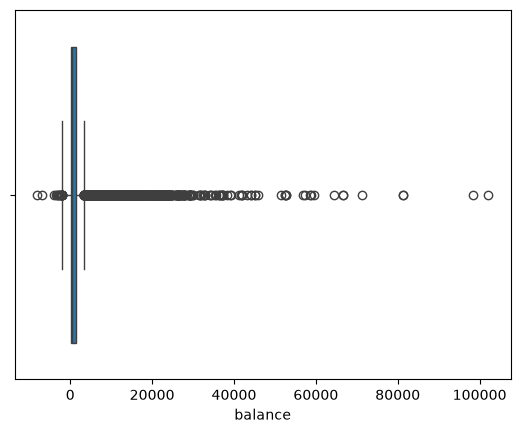

In [48]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.boxplot(data=df,x = "balance")

In [49]:
negative_pdays = (df['pdays'] < 0).sum()


total_count = len(df)

#Calculate the percentage
nagative_percentage = (negative_pdays / total_count) * 100

print(f"Number of Negative values: {negative_pdays}")
print(f"Percentage of negative values: {nagative_percentage}")

Number of Negative values: 36954
Percentage of negative values: 81.73674548229414


In [50]:
# Replace -1 with 999 or a high placeholder
df["pdays"] = df["pdays"].replace(-1, 999)

In [51]:
df.to_csv("Modular_coding.csv")

### Categorical Encoding

In [52]:
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,Target
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,999,0,unknown,0
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,999,0,unknown,0
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,999,0,unknown,0
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,999,0,unknown,0
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,999,0,unknown,0


In [53]:
df_encoded = pd.get_dummies(
    df,
    columns=["job", "marital", "education","default", "housing", "loan", "contact", "month","poutcome"],
    dtype=int
)

print(df_encoded.head())

   age  balance  day  duration  campaign  pdays  previous  Target  job_admin.  \
0   58     2143    5       261         1    999         0       0           0   
1   44       29    5       151         1    999         0       0           0   
2   33        2    5        76         1    999         0       0           0   
3   47     1506    5        92         1    999         0       0           0   
4   33        1    5       198         1    999         0       0           0   

   job_blue-collar  ...  month_jun  month_mar  month_may  month_nov  \
0                0  ...          0          0          1          0   
1                0  ...          0          0          1          0   
2                0  ...          0          0          1          0   
3                1  ...          0          0          1          0   
4                0  ...          0          0          1          0   

   month_oct  month_sep  poutcome_failure  poutcome_other  poutcome_success  \
0      

### Feature Scaling

In [54]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

columns_to_scale = [
    "age",
    "balance",
    "duration",
    "campaign"
]

df[columns_to_scale] = scaler.fit_transform(
    df[columns_to_scale]
)

#### Feature Transformation

In [55]:
import numpy as np

df["balance_log"] = np.log1p(df["balance"].clip(lower=0))

#### Feature Creation

In [56]:
## Age Grop

df["age_group"] = pd.cut(
    df["age"],
    bins=[0, 25, 35, 50, 100],
    labels=["Young", "Adult", "Middle_Aged","Senior"],
    right=True
)

## Total previous contact and current campaing contacts
df["total_contacts"] = (
    df['campaign'] + df['previous']
)

print(df[[
    "age",
    "age_group",
    "campaign",
    "previous",
    "total_contacts"
]].head())

        age age_group  campaign  previous  total_contacts
0  1.606965     Young -0.569351         0       -0.569351
1  0.288529     Young -0.569351         0       -0.569351
2 -0.747384       NaN -0.569351         0       -0.569351
3  0.571051     Young -0.569351         0       -0.569351
4 -0.747384       NaN -0.569351         0       -0.569351


#### Feature Extraction

In [ ]:
# df["date"] = pd.to_datetime(df["date"])

# df['year'] = df['date'].dt.year
# df['year'] = df['date'].dt.month
# df['year'] = df['date'].dt.day
# df["day_of_week"] = df['date'].dt.dayofweek


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,Target,balance_log,age_group,total_contacts
0,1.606965,management,married,tertiary,no,0.256419,yes,no,unknown,5,may,0.011016,-0.569351,999,0,unknown,0,0.228266,Young,-0.569351
1,0.288529,technician,single,secondary,no,-0.437895,yes,no,unknown,5,may,-0.416127,-0.569351,999,0,unknown,0,0.000000,Young,-0.569351
2,-0.747384,entrepreneur,married,secondary,no,-0.446762,yes,yes,unknown,5,may,-0.707361,-0.569351,999,0,unknown,0,0.000000,NaN,-0.569351


### Binning

In [62]:

df["balance_category"] = pd.cut(
    df["balance"],
    bins=[-float("inf"), 0, 1000, 5000, float("inf")],
    labels=[
        "Negative",
        "Low",
        "Medium",
        "High"
    ]
)

print(df[["balance", "balance_category"]].head())


    balance balance_category
0  0.256419              Low
1 -0.437895         Negative
2 -0.446762         Negative
3  0.047205              Low
4 -0.447091         Negative


In [63]:

# Remove an identifier if it has no predictive meaning
# df = df.drop(columns=["customer_id"])

# Correlation among numerical features
numeric_df = df.select_dtypes(include="number")

corr = numeric_df.corr()

print(corr)


                     age   balance       day  duration  campaign     pdays  \
age             1.000000  0.097783 -0.009120 -0.004648  0.004760 -0.008804   
balance         0.097783  1.000000  0.004503  0.021560 -0.014578 -0.037360   
day            -0.009120  0.004503  1.000000 -0.030206  0.162490  0.079074   
duration       -0.004648  0.021560 -0.030206  1.000000 -0.084570 -0.005090   
campaign        0.004760 -0.014578  0.162490 -0.084570  1.000000  0.108306   
pdays          -0.008804 -0.037360  0.079074 -0.005090  0.108306  1.000000   
previous        0.001288  0.016674 -0.051710  0.001203 -0.032855 -0.528910   
Target          0.025155  0.052838 -0.028348  0.394521 -0.073172 -0.178898   
balance_log     0.102173  0.914663  0.012562  0.024358 -0.014294 -0.038768   
total_contacts  0.003115  0.009605  0.017486 -0.032973  0.372590 -0.447434   

                previous    Target  balance_log  total_contacts  
age             0.001288  0.025155     0.102173        0.003115  
balance  

In [65]:

from sklearn.model_selection import train_test_split

X = df.drop(columns=["Target"])
y = df["Target"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)


Training shape: (36168, 21)
Testing shape: (9043, 21)


In [68]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

# Choose prediction-time-available features
X = df.drop(columns=["Target", "duration"], errors="ignore")
y = df['Target']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

num_cols = X_train.select_dtypes(
    include="number"
).columns.tolist()

cat_cols = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, num_cols),
    ("cat", categorical_pipeline, cat_cols)
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)

print("Test accuracy:", model.score(X_test, y_test))


C:\Users\mdsal\AppData\Local\Temp\ipykernel_11928\2829730463.py:27: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X_train.select_dtypes(


Test accuracy: 0.892734711931881


In [69]:
df.head(3)

,age,job,marital,education,default,balance,housing,loan,contact,day,...,campaign,pdays,previous,poutcome,Target,balance_log,age_group,total_contacts,balacne_category,balance_category
0,1.606965,management,married,tertiary,no,0.256419,yes,no,unknown,5,...,-0.569351,999,0,unknown,0,0.228266,Young,-0.569351,Low,Low
1,0.288529,technician,single,secondary,no,-0.437895,yes,no,unknown,5,...,-0.569351,999,0,unknown,0,0.000000,Young,-0.569351,Negative,Negative
2,-0.747384,entrepreneur,married,secondary,no,-0.446762,yes,yes,unknown,5,...,-0.569351,999,0,unknown,0,0.000000,NaN,-0.569351,Negative,Negative


In [70]:
df.to_csv("Model_Trainer.csv")